## 02. QPSK in additive white Gaussian noise

Every digital link is ultimately judged by one number: the fraction of bits
that arrive wrong, the **bit error rate** (BER). Notebook 01 set up the
frequency-domain view that OFDM relies on. Here we set echoes aside and study
the simplest link that still has every essential part: bits are mapped to
complex **QPSK** symbols, the symbols are corrupted by **additive white
Gaussian noise**, and the receiver decides which bits were sent.

The goal is one plot: simulated BER against $E_b/N_0$, on top of the
theoretical curve $Q\big(\sqrt{2E_b/N_0}\big)$. A match confirms that the
modulation, the noise model, and the energy bookkeeping are all correct, and
the same building blocks are reused in every later notebook.

### Setup

The building blocks live in the `ofdm` package: `modulation.py` maps bits to
symbols and back, `channel.py` adds noise, and `metrics.py` measures errors and
provides the theory curve. This notebook connects them and explains why they work.

In [1]:
%load_ext autoreload
%autoreload 2
import numpy as np
import matplotlib.pyplot as plt

from ofdm.channel import add_awgn
from ofdm.metrics import bit_error_rate, qpsk_ber_theory
from ofdm.modulation import qpsk_demodulate, qpsk_modulate

rng = np.random.default_rng(0)

### QPSK

A radio signal at a fixed carrier frequency is described by two numbers: how
much cosine and how much sine it contains. We pack these into one complex
number $s = I + jQ$, the **in-phase** and **quadrature** components, where
engineers write $j = \sqrt{-1}$. Every transmitted symbol is a point in the
complex plane.

QPSK carries 2 bits per symbol. The first bit sets the sign of the real part
and the second sets the sign of the imaginary part, with $0 \mapsto +$ and
$1 \mapsto -$:

$$s = \frac{(1 - 2b_1) + j\,(1 - 2b_2)}{\sqrt{2}}.$$

| Bits | Symbol |
|---|---|
| 00 | $(1 + j)/\sqrt{2}$ |
| 01 | $(1 - j)/\sqrt{2}$ |
| 10 | $(-1 + j)/\sqrt{2}$ |
| 11 | $(-1 - j)/\sqrt{2}$ |

The factor $1/\sqrt{2}$ gives every symbol unit energy, $E_s = |s|^2 = 1$,
which fixes the scale for the noise bookkeeping below. Since two bits share
each symbol, each bit gets $E_b = E_s/2 = 1/2$.

**Gray labeling.** Points in adjacent quadrants differ in exactly one bit.
Noise most often pushes a symbol into an adjacent quadrant, so the most likely
symbol error costs one bit rather than two.

**Detection.** The receiver picks the constellation point nearest to the
received value $r$. For Gaussian noise, the nearest point is also the most
likely one, so this decision is optimal. By symmetry the decision regions are
the four quadrants, and each bit is decided separately from the sign of one
component:

$$\hat b_1 = \mathbb{1}[\operatorname{Re} r < 0], \qquad \hat b_2 = \mathbb{1}[\operatorname{Im} r < 0].$$

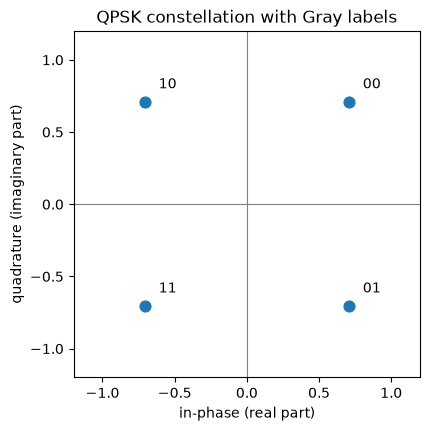

In [2]:
pairs = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
symbols = qpsk_modulate(pairs.ravel())

fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.axhline(0, color="gray", lw=0.8)
ax.axvline(0, color="gray", lw=0.8)
ax.scatter(symbols.real, symbols.imag, s=60, zorder=3)
for (b1, b2), s in zip(pairs, symbols):
    ax.annotate(f"{b1}{b2}", (s.real, s.imag),
                textcoords="offset points", xytext=(10, 10))
ax.set_xlim(-1.2, 1.2)
ax.set_ylim(-1.2, 1.2)
ax.set_aspect("equal")
ax.set_xlabel("in-phase (real part)")
ax.set_ylabel("quadrature (imaginary part)")
ax.set_title("QPSK constellation with Gray labels")
plt.show()

### Additive white Gaussian noise

The receiver observes

$$r = s + n,$$

where $n$ is complex Gaussian noise whose real and imaginary parts are
independent $\mathcal{N}(0, N_0/2)$, and independent from one symbol to the
next. Its total average energy is $\mathbb{E}|n|^2 = N_0$. This model,
**additive white Gaussian noise** (AWGN), describes thermal noise in the
receiver's electronics: the sum of a huge number of tiny independent
fluctuations, which is Gaussian by the central limit theorem.

**Signal-to-noise ratio per bit.** The strength of the signal relative to the
noise is measured by

$$\frac{E_b}{N_0} = \frac{E_s / k}{N_0},$$

where $k$ is the number of bits per symbol, $k = 2$ for QPSK. Normalizing by
bits per symbol lets modulations that carry different numbers of bits be
compared fairly. It is usually quoted in decibels, $10\log_{10}(E_b/N_0)$.

**From $E_b/N_0$ to noise.** To simulate at a given $E_b/N_0$ in dB,
`add_awgn` works backwards:

1. Convert from decibels: $\gamma = 10^{\text{dB}/10}$.
2. Energy per bit: $E_b = E_s / k = 1/k$.
3. Noise level: $N_0 = E_b / \gamma$.
4. Standard deviation per component: $\sigma = \sqrt{N_0 / 2}$.
5. Noise: $n = \sigma\,(g_1 + j\,g_2)$, with $g_1, g_2$ independent standard normals.

For QPSK at 10 dB, this gives $N_0 = 0.05$ and $\sigma \approx 0.16$, small
next to the symbol components $\pm 1/\sqrt{2} \approx \pm 0.71$.

The plots below show 2000 received symbols at three noise levels, with the
transmitted constellation in red.

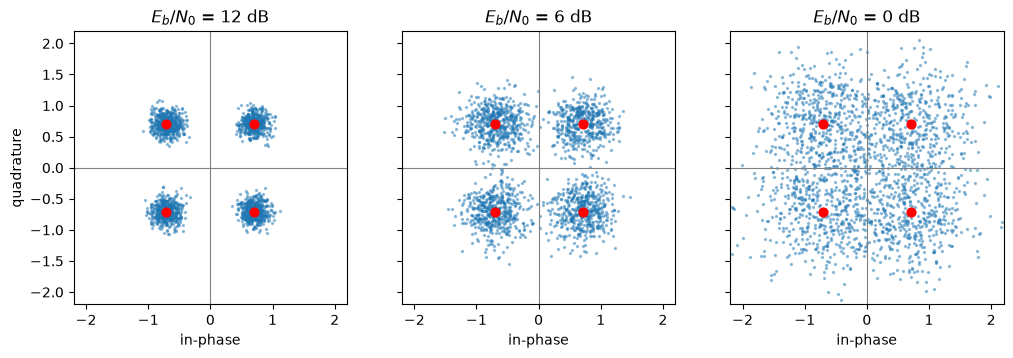

In [3]:
ebn0_show = [12, 6, 0]
n_sym = 2000
bits = rng.integers(0, 2, size=2 * n_sym)
tx = qpsk_modulate(bits)

fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharex=True, sharey=True)
for ax, ebn0_db in zip(axes, ebn0_show):
    r = add_awgn(tx, ebn0_db, bits_per_symbol=2, rng=rng)
    ax.scatter(r.real, r.imag, s=2, alpha=0.4)
    ax.scatter(symbols.real, symbols.imag, s=40, color="red", zorder=3)
    ax.axhline(0, color="gray", lw=0.8)
    ax.axvline(0, color="gray", lw=0.8)
    ax.set_aspect("equal")
    ax.set_title(f"$E_b/N_0$ = {ebn0_db} dB")
    ax.set_xlabel("in-phase")
axes[0].set_ylabel("quadrature")
axes[0].set_xlim(-2.2, 2.2)
axes[0].set_ylim(-2.2, 2.2)
plt.show()

At 12 dB the clouds are tight and sit well inside their quadrants. As the
noise grows they spread, and at 0 dB they spill across the axes. Every
received value that lands in the wrong quadrant produces a bit error, which
is exactly what the next section computes.

### Theoretical bit error rate

By symmetry, every symbol and every bit has the same error probability, so we
condition on the transmitted symbol $s = (1 + j)/\sqrt{2}$, the bits 00.

**First bit.** It is decided from the sign of the real part,
$\operatorname{Re} r = 1/\sqrt{2} + n_I$, where $n_I \sim \mathcal{N}(0, N_0/2)$.
It is wrong exactly when the noise pushes the real part across zero:

$$
P_b = \Pr\!\Big(n_I < -\tfrac{1}{\sqrt{2}}\Big)
= \Pr\!\Big(n_I > \tfrac{1}{\sqrt{2}}\Big)
= Q\!\left(\frac{1/\sqrt{2}}{\sqrt{N_0/2}}\right)
= Q\!\left(\sqrt{\tfrac{1}{N_0}}\right),
$$

where $Q(x) = \Pr(Z > x)$ for $Z \sim \mathcal{N}(0, 1)$ is the Gaussian tail
probability, and the second step uses the symmetry of the Gaussian.

**In terms of $E_b/N_0$.** With $E_b = 1/2$, we have $1/N_0 = 2E_b/N_0$, so

$$P_b = Q\!\left(\sqrt{\frac{2E_b}{N_0}}\right).$$

**Second bit.** It depends only on the imaginary noise $n_Q$, which has the
same distribution and is independent of $n_I$. So it has the same error
probability, and the overall bit error rate is $P_b$.

**Remarks.**
- QPSK behaves as two independent binary channels, one on each axis. It
  carries twice the bits of one-axis binary signaling (BPSK) at the same
  bit error rate for a given $E_b/N_0$.
- The argument of $Q$ is the distance from a symbol to the nearest decision
  boundary, $1/\sqrt{2}$, divided by the noise standard deviation per axis,
  $\sqrt{N_0/2}$. This "distance over noise" form recurs throughout
  communications.
- A symbol is correct only if both of its bits are, so the symbol error rate
  is $1 - (1 - P_b)^2 = 2P_b - P_b^2$.

### Simulation

The simulation is a Monte Carlo experiment: draw random bits, pass them
through the link, and count the errors. The measured bit error rate is the
number of errors divided by the number of bits sent.

**How many bits are enough?** The number of errors is approximately Poisson
with mean $n P_b$, so its relative standard deviation is $1/\sqrt{n P_b}$:
one over the square root of the expected number of errors. Collecting about
100 errors gives a relative accuracy of about 10%, whatever the BER. At 0 dB,
where $P_b \approx 0.08$, that takes about 1,300 bits. At 10 dB, where
$P_b \approx 4 \times 10^{-6}$, it takes about 25 million.

As a first check, one batch of a million bits at 4 dB:

In [8]:
bits = rng.integers(0, 2, size=1_000_000)
r = add_awgn(qpsk_modulate(bits), 4, bits_per_symbol=2, rng=rng)

print(f"simulated: {bit_error_rate(bits, qpsk_demodulate(r)):.4e}")
print(f"theory:    {qpsk_ber_theory(4):.4e}")

simulated: 1.2634e-02
theory:    1.2501e-02


For the full sweep, a fixed number of bits would be wasteful at low $E_b/N_0$
and too few at high $E_b/N_0$. Instead, the loop sends bits in batches and
stops once it has counted 100 errors, with a cap on the total.

In [9]:
ebn0_db = np.arange(0, 11)
target_errors = 100
batch_bits = 1_000_000
max_bits = 50_000_000

ber_sim = np.zeros(len(ebn0_db))
for idx, snr_db in enumerate(ebn0_db):
    n_errors = 0
    n_bits = 0
    while n_errors < target_errors and n_bits < max_bits:
        bits = rng.integers(0, 2, size=batch_bits)
        r = add_awgn(qpsk_modulate(bits), snr_db, bits_per_symbol=2, rng=rng)
        n_errors += np.count_nonzero(bits != qpsk_demodulate(r))
        n_bits += batch_bits
    ber_sim[idx] = n_errors / n_bits
    print(f"{snr_db:>2} dB: {n_errors:>6,} errors in {n_bits:>11,} bits, "
          f"BER = {ber_sim[idx]:.2e}")

 0 dB: 78,342 errors in   1,000,000 bits, BER = 7.83e-02
 1 dB: 56,544 errors in   1,000,000 bits, BER = 5.65e-02
 2 dB: 37,362 errors in   1,000,000 bits, BER = 3.74e-02
 3 dB: 22,979 errors in   1,000,000 bits, BER = 2.30e-02
 4 dB: 12,448 errors in   1,000,000 bits, BER = 1.24e-02
 5 dB:  5,996 errors in   1,000,000 bits, BER = 6.00e-03
 6 dB:  2,381 errors in   1,000,000 bits, BER = 2.38e-03
 7 dB:    771 errors in   1,000,000 bits, BER = 7.71e-04
 8 dB:    189 errors in   1,000,000 bits, BER = 1.89e-04
 9 dB:    116 errors in   3,000,000 bits, BER = 3.87e-05
10 dB:    100 errors in  24,000,000 bits, BER = 4.17e-06


### Results

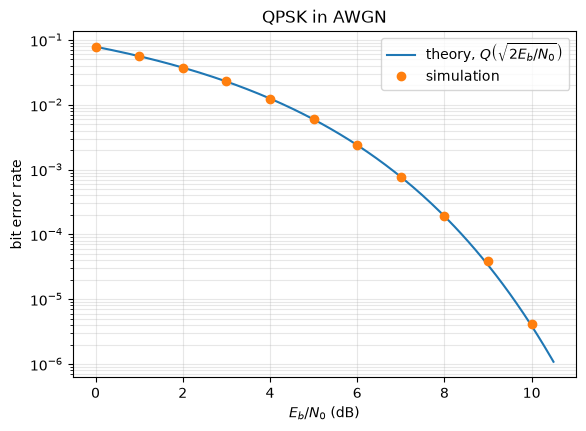

In [10]:
ebn0_fine = np.linspace(0, 10.5, 200)

fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.semilogy(ebn0_fine, qpsk_ber_theory(ebn0_fine),
            label=r"theory, $Q\left(\sqrt{2E_b/N_0}\right)$")
ax.semilogy(ebn0_db, ber_sim, "o", label="simulation")
ax.set_xlabel(r"$E_b/N_0$ (dB)")
ax.set_ylabel("bit error rate")
ax.set_title("QPSK in AWGN")
ax.grid(True, which="both", alpha=0.3)
ax.legend()
plt.show()

In [11]:
for snr_db, sim, theory in zip(ebn0_db, ber_sim, qpsk_ber_theory(ebn0_db)):
    print(f"{snr_db:>2} dB: simulated {sim:.2e}, theory {theory:.2e}, "
          f"ratio {sim / theory:.2f}")

 0 dB: simulated 7.83e-02, theory 7.86e-02, ratio 1.00
 1 dB: simulated 5.65e-02, theory 5.63e-02, ratio 1.00
 2 dB: simulated 3.74e-02, theory 3.75e-02, ratio 1.00
 3 dB: simulated 2.30e-02, theory 2.29e-02, ratio 1.00
 4 dB: simulated 1.24e-02, theory 1.25e-02, ratio 1.00
 5 dB: simulated 6.00e-03, theory 5.95e-03, ratio 1.01
 6 dB: simulated 2.38e-03, theory 2.39e-03, ratio 1.00
 7 dB: simulated 7.71e-04, theory 7.73e-04, ratio 1.00
 8 dB: simulated 1.89e-04, theory 1.91e-04, ratio 0.99
 9 dB: simulated 3.87e-05, theory 3.36e-05, ratio 1.15
10 dB: simulated 4.17e-06, theory 3.87e-06, ratio 1.08


The simulated points sit on the theoretical curve across five orders of
magnitude, and the ratios stay within the roughly 10% accuracy expected from
collecting 100 errors per point. Note the waterfall shape: at the high end,
each extra decibel cuts the error rate by a large factor.

### Summary

- QPSK maps two bits to one unit-energy complex symbol, with Gray labeling so
  that the most likely mistake costs only one bit.
- In AWGN, nearest-point detection reduces to two independent sign decisions,
  and each bit has error probability $Q\big(\sqrt{2E_b/N_0}\big)$.
- Simulation matches theory from 0 to 10 dB within Monte Carlo accuracy. This
  validates the modulation, the noise model, and the $E_b/N_0$ bookkeeping
  that every later notebook builds on.

**Next:** notebook 03 places these symbols on $N$ frequency bins with an
inverse FFT, adds the cyclic prefix from notebook 01, and measures exactly
what the prefix costs.